Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping # A callback that stops training when the model performance stops improving (usually on validation data). Prevents overfitting


| Step                     | Library Used                                | Purpose                                        |
| ------------------------ | ------------------------------------------- | ---------------------------------------------- |
| 1. Data loading/cleaning | `pandas`                                    | Read and process CSV or Excel files            |
| 2. Data visualization    | `matplotlib`, `seaborn`                     | Explore patterns, outliers                     |
| 3. Preprocessing         | `train_test_split`, `StandardScaler`        | Split data & normalize features                |
| 4. Model building        | `LogisticRegression` / `Sequential + Dense` | Create machine learning / deep learning models |
| 5. Evaluation            | `confusion_matrix`, `accuracy_score`, etc.  | Measure performance                            |
| 6. Optimization          | `EarlyStopping`                             | Stop training when no longer improving         |


Step 1: Dataset Exploration

In [ ]:
# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
col_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
             'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, names=col_names)

# Overview
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nClass Distribution:\n", df['Outcome'].value_counts())
df.head()


Shape: (768, 9)

Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class Distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Step 2: Feature Visualization

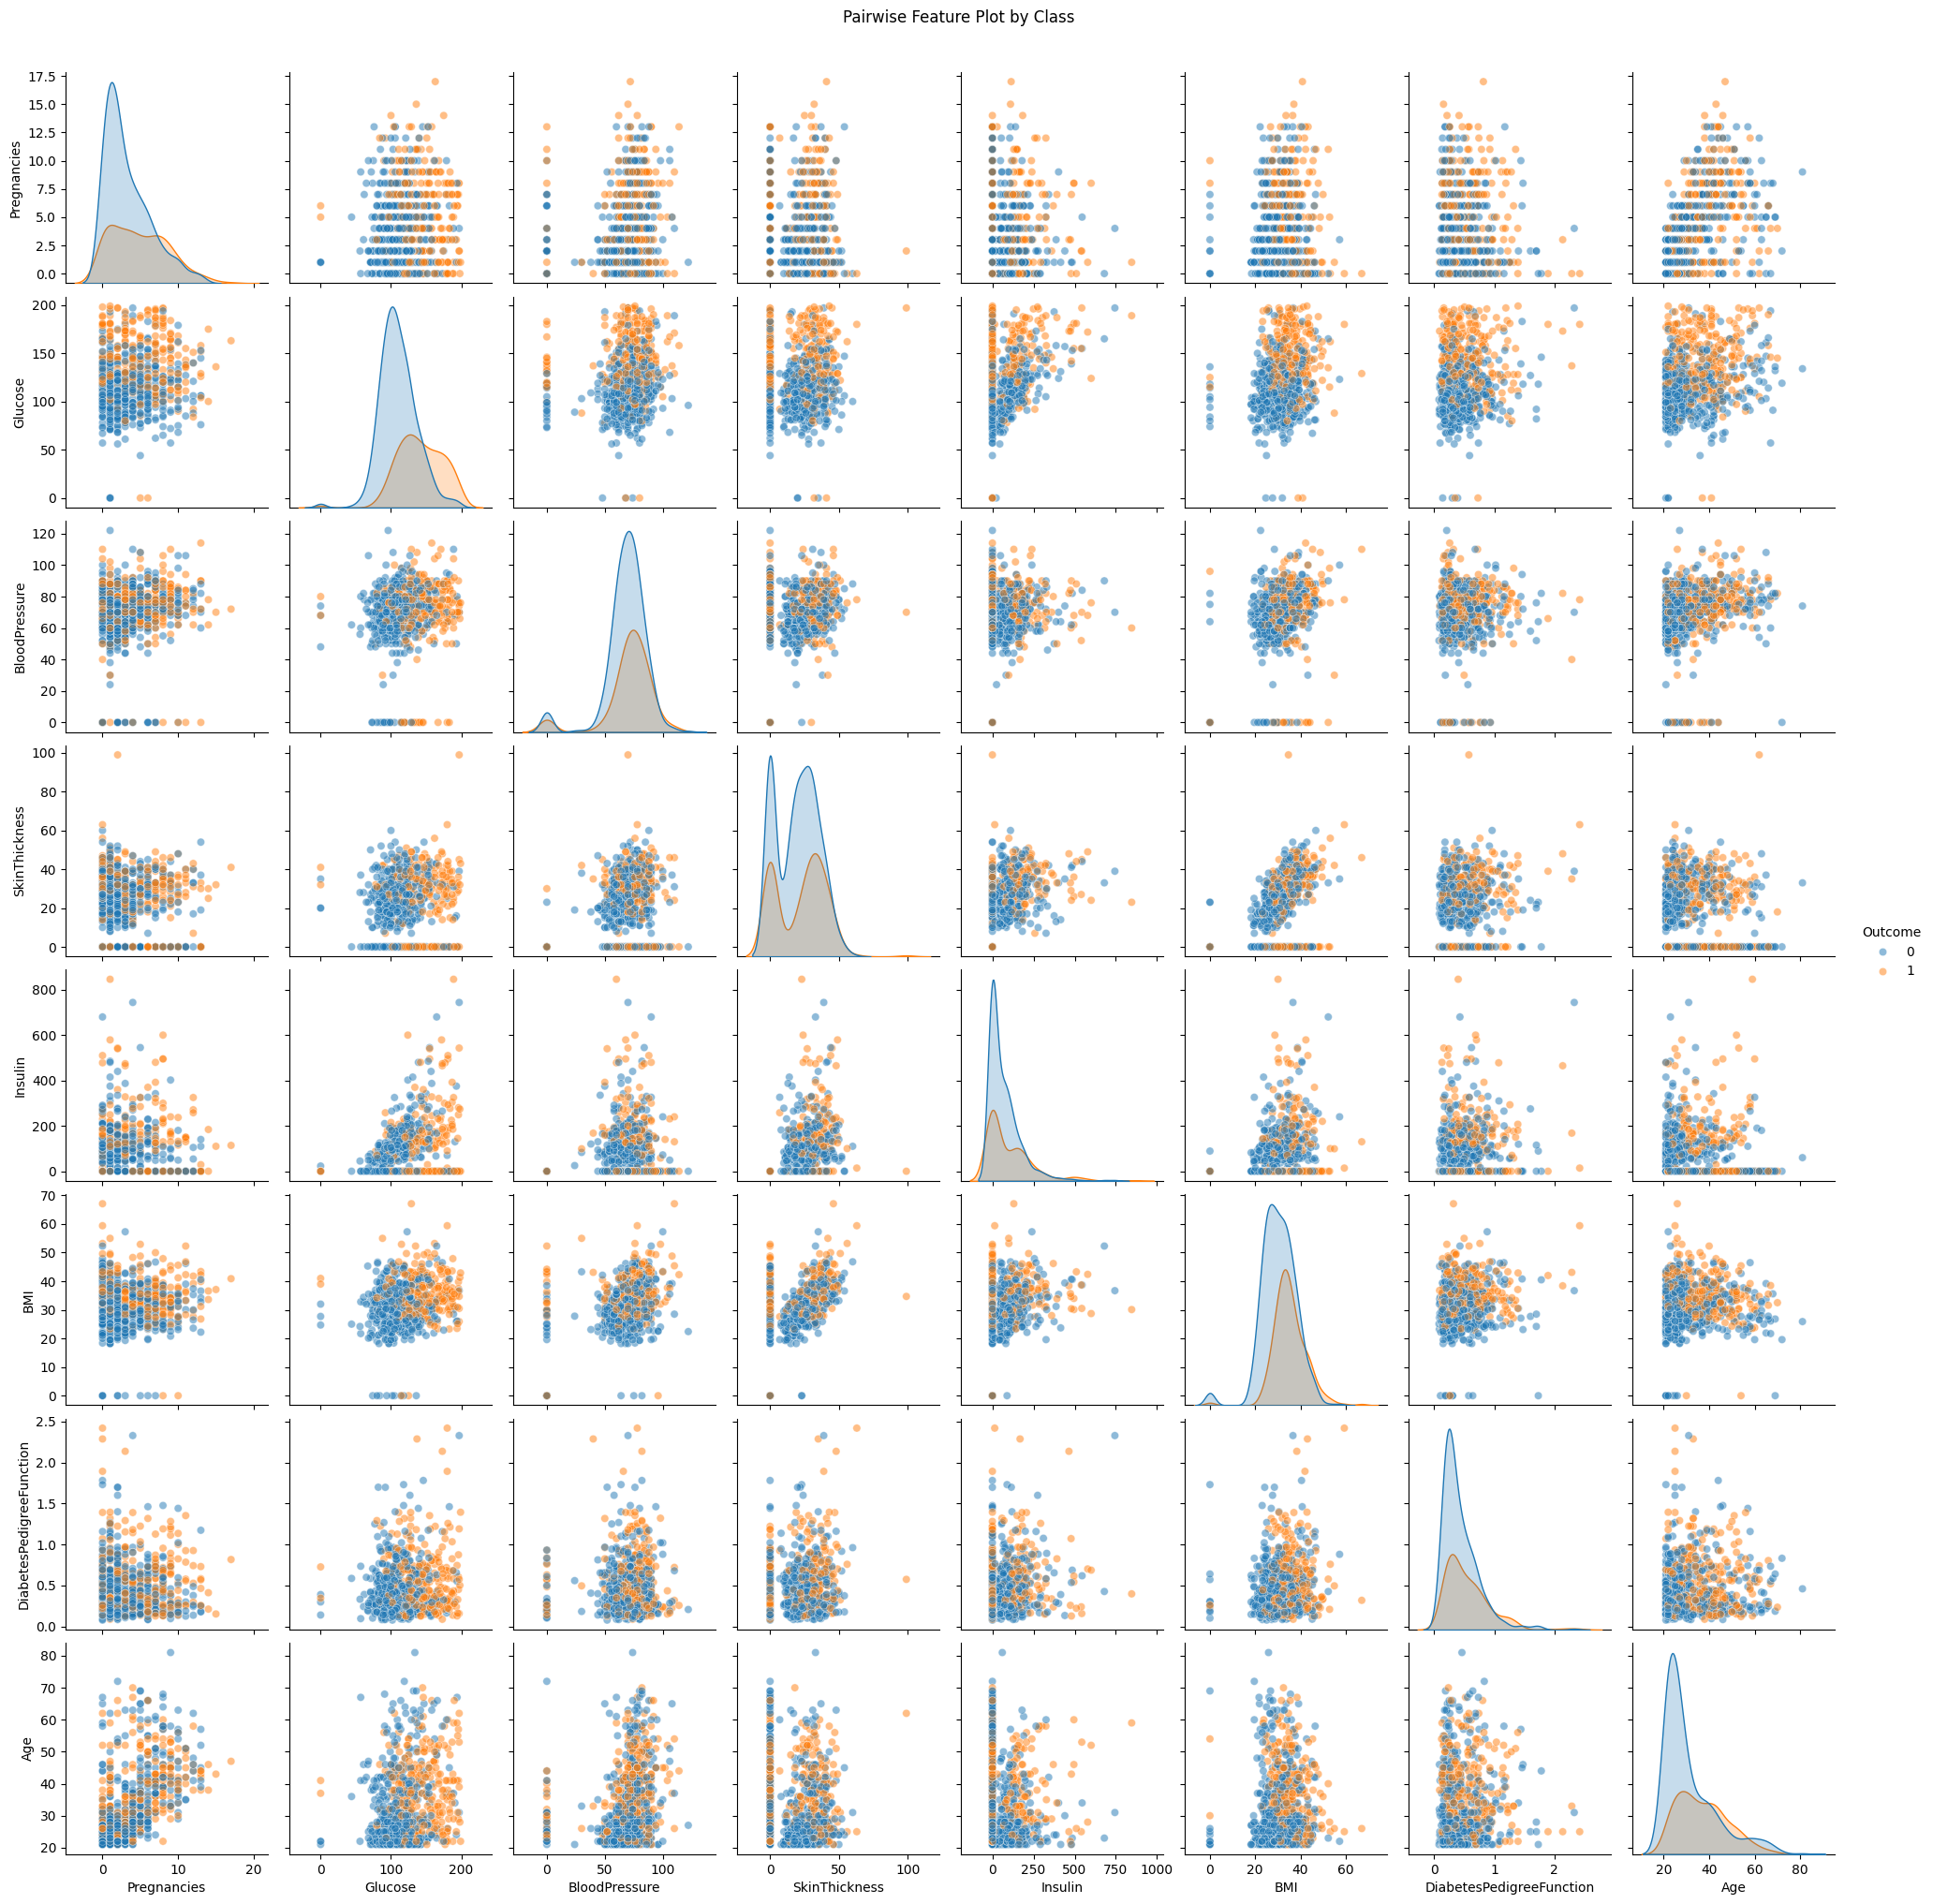

In [ ]:
sns.pairplot(df, hue='Outcome', diag_kind='kde', plot_kws={'alpha': 0.5})
plt.suptitle("Pairwise Feature Plot by Class", y=1.02)
plt.show()


Step 3: ML Approach (Logistic Regression)

Manual Feature Engineering

In [ ]:
# Data Split
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression Model
lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)

# Predictions & Evaluation
y_pred_lr = lr.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))


Accuracy: 0.7532467532467533
Confusion Matrix:
 [[79 20]
 [18 37]]
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.81        99
           1       0.65      0.67      0.66        55

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.75       154



Step 4: DL Approach (Feedforward Neural Network)
Feature Learning

In [ ]:
# Build Model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train Model
history = model.fit(X_train_scaled, y_train, validation_split=0.2,
                    epochs=100, batch_size=16, verbose=0,
                    callbacks=[EarlyStopping(patience=10, restore_best_weights=True)])

# Evaluate
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print("DL Model Test Accuracy:", accuracy)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7251 - loss: 0.5666 
DL Model Test Accuracy: 0.7402597665786743


Learning Curves

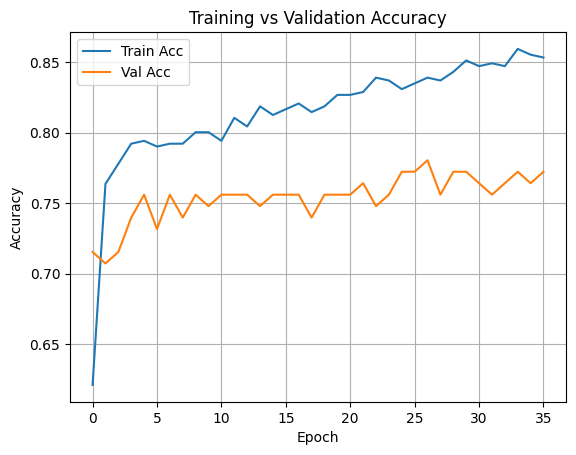

In [ ]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Example Input
sample = np.array([[1, 150, 70, 30, 0, 35.0, 0.5, 25]])  # Manually created input
sample_scaled = scaler.transform(sample)
prediction = model.predict(sample_scaled)
print("Predicted probability of diabetes:", prediction[0][0])
print("Class:", int(prediction[0][0] > 0.5))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
Predicted probability of diabetes: 0.88383406
Class: 1
